# Falsas alarmas: el test de la enfermedad rara

**Jornada 3 · Bloque 3.4 · Falsas alarmas y datos torturados**

**Cómo usarlo.** En Google Colab: menú *Entorno de ejecución → Ejecutar todo* (en inglés, *Runtime → Run all*); la primera vez tarda unos segundos en descargar los datos del curso. En Jupyter: *Ejecutar → Ejecutar todo*. Luego mueve los controles. No hace falta tocar el código: está escondido y solo carga los datos y dibuja. Si quieres verlo, pulsa los tres puntos que aparecen en las celdas ocultas.

In [1]:
# Preparación: busca la carpeta del proyecto, carga el estilo del curso y los datos.
# No hace falta tocar nada.
import sys
from pathlib import Path


def buscar_proyecto():
    """La carpeta que contiene datos/, scripts/estilo.py y cuadernos/laboratorio.py."""
    aqui = Path.cwd()
    candidatas = [aqui, *aqui.parents,
                  Path("/content/cursos-analitica-datos"),               # Colab, subida a mano
                  Path("/content/drive/MyDrive/cursos-analitica-datos")]  # Colab, desde Drive
    for carpeta in candidatas:
        if (carpeta / "scripts" / "estilo.py").exists() and (carpeta / "cuadernos" / "laboratorio.py").exists():
            return carpeta
    if "google.colab" in sys.modules:  # en Colab, descarga una vez el material público del curso
        import subprocess
        destino = Path("/content/curso-analitica-cuadernos")
        if not destino.exists():
            subprocess.run(["git", "clone", "--quiet", "--depth", "1",
                            "https://github.com/castrorbea/curso-analitica-cuadernos.git", str(destino)], check=True)
        return destino
    raise FileNotFoundError("No encuentro el proyecto: abre este cuaderno desde la carpeta cuadernos/.")


PROYECTO = buscar_proyecto()
DATOS = PROYECTO / "datos"
for ruta in (PROYECTO / "scripts", PROYECTO / "cuadernos"):  # ../scripts y la carpeta de este cuaderno
    if str(ruta) not in sys.path:
        sys.path.insert(0, str(ruta))

import ipywidgets as widgets
from IPython.display import display

import estilo  # paleta, tipografía y formato numérico español del curso
import laboratorio as lab  # cálculos y gráficos de estos cuadernos

try:  # en Google Colab, los controles necesitan activar este gestor
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

ESTILO = {"description_width": "initial"}
BOTONES = {"description_width": "initial", "button_width": "auto"}

resumen = lab.cargar_test(DATOS)
print("Datos listos: los valores del curso son 1 % de enfermos, 95 % de sensibilidad y 95 % de especificidad")

Datos listos: los valores del curso son 1 % de enfermos, 95 % de sensibilidad y 95 % de especificidad


## La pregunta

Un test «fiable al 95 %» le da positivo a alguien. ¿Qué probabilidad hay de que esté enfermo? Si has
dicho 95 %, estás en buena compañía: es lo que contesta casi todo el mundo, incluidos bastantes médicos.

## El experimento

El árbol reparte 1.000 personas según tengan o no la enfermedad y según lo que diga el test. Mueve la
prevalencia (cuánta gente la tiene), la sensibilidad (a cuántos enfermos detecta) y la especificidad
(a cuántos sanos deja en paz). El estado inicial es el del curso: 1 %, 95 % y 95 %. Las cifras con
decimales son normales: son medias sobre 1.000 personas.

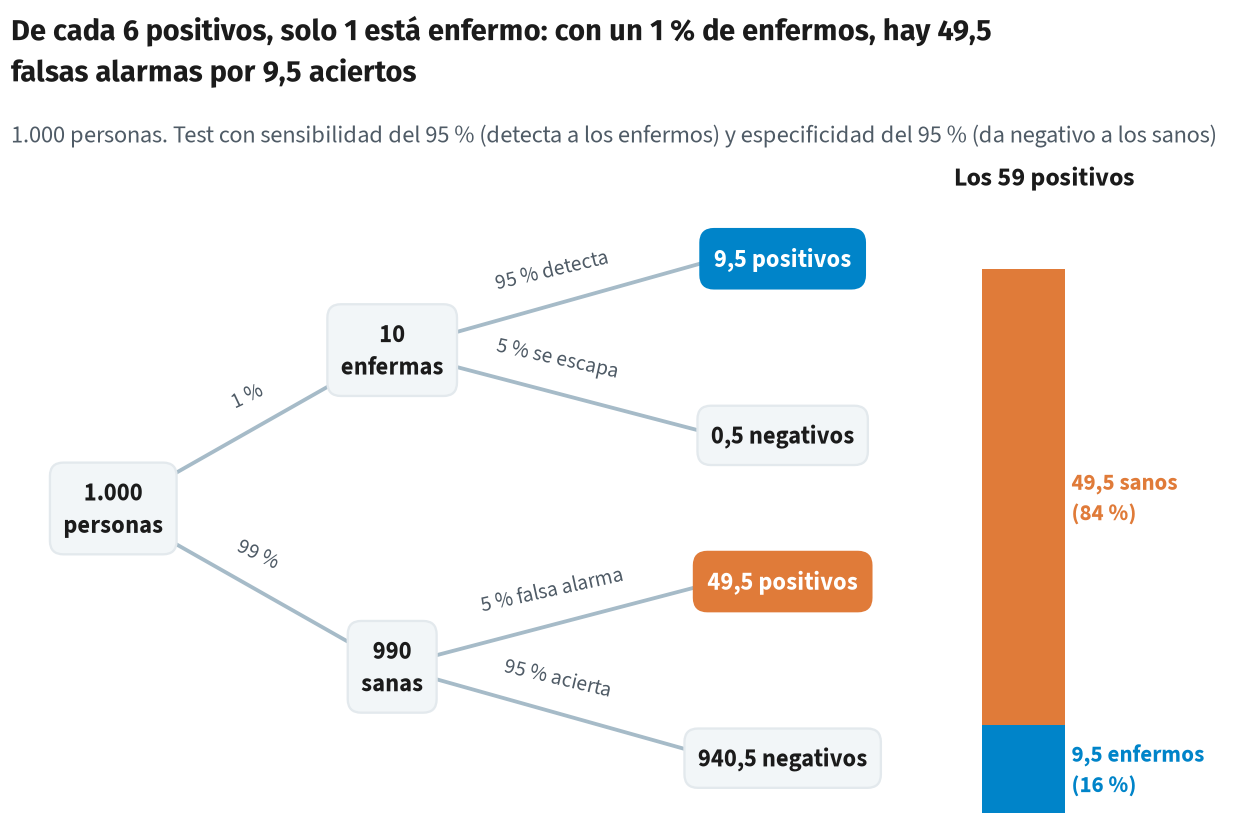

In [2]:
# El experimento: cuántos positivos son de verdad.
def porcentaje(x):
    return estilo.num(x, 1 if x != int(x) else 0) + " %"


prevalencia = widgets.SelectionSlider(
    options=[(porcentaje(x), x) for x in lab.OPCIONES_PREVALENCIA], value=1, continuous_update=False,
    description="Prevalencia (enfermos):", style=ESTILO, layout=widgets.Layout(width="550px"))
sensibilidad = widgets.SelectionSlider(
    options=[(porcentaje(x), x) for x in lab.OPCIONES_ACIERTO], value=95, continuous_update=False,
    description="Sensibilidad (detecta enfermos):", style=ESTILO, layout=widgets.Layout(width="550px"))
especificidad = widgets.SelectionSlider(
    options=[(porcentaje(x), x) for x in lab.OPCIONES_ACIERTO], value=95, continuous_update=False,
    description="Especificidad (respeta a los sanos):", style=ESTILO, layout=widgets.Layout(width="550px"))


def dibujar(prevalencia, sensibilidad, especificidad):
    lab.mostrar(lab.dibujar_falsas_alarmas(prevalencia, sensibilidad, especificidad))


grafico = widgets.interactive_output(
    dibujar, {"prevalencia": prevalencia, "sensibilidad": sensibilidad, "especificidad": especificidad})
display(widgets.VBox([prevalencia, sensibilidad, especificidad, grafico]))

## Qué observar

1. Con los valores iniciales, ¿cuántos positivos hay y cuántos de ellos están enfermos?
2. Sube la sensibilidad al 99,9 %. ¿Mejora mucho el «de cada N positivos»? ¿Y si subes la especificidad?
3. Sube la prevalencia al 20 % o al 50 %. ¿Qué le pasa al mismo test?
4. ¿Por qué nadie llama a la policía cuando salta la alarma de un coche?

## Mensaje clave

> **Quien busca lo suficiente encuentra algo; eso no lo convierte en verdad.**

En versión test: cuando lo que se busca es raro, la mayoría de los avisos son falsos, aunque el test
sea bueno.

## Para curiosos

En el avanzado se elige el umbral de una alarma según lo que cuesta cada error: no es lo mismo un falso
positivo que obliga a repetir una prueba que un falso negativo que deja pasar un problema.